In [3]:
from query_lithuanian_addresses import sample_addresses
import matplotlib.pyplot as plt
import geopandas as gpd

vilnius = sample_addresses("Vilnius", 100)
vilnius = gpd.GeoDataFrame(
    vilnius, geometry=gpd.points_from_xy(vilnius.longitude, vilnius.latitude), crs="EPSG:4326"
)

kaunas = sample_addresses("Kaunas", 100)

Saved 100 address points to vilnius_100_addresses.csv
Saved 100 address points to kaunas_100_addresses.csv


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

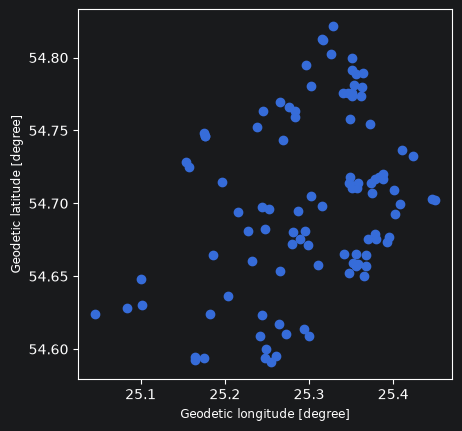

In [5]:
vilnius.plot()
plt.title("Vilnius addresses")
plt.show()

In [2]:
import requests

URL = (
    "https://digital.kaunas.lt/arcgis/rest/services/"
    "Bendra/Bendri_duomenys/MapServer/3/query"
)

# kaunas is the DataFrame returned by the earlier sampling script.
street_id = int(kaunas["GTV_ID"].dropna().iloc[0])

response = requests.get(URL, params={
    "where": f"GTV_ID = {street_id}",
    "outFields": "GTV_ID,GAT_KODAS,GTV_PAV,GTV_PAV_PI",
    "returnGeometry": "false",
    "f": "json",
}, timeout=60)
response.raise_for_status()

data = response.json()
if "error" in data:
    raise RuntimeError(data["error"])

for feature in data["features"]:
    print(feature["attributes"])

{'GTV_ID': 9435, 'GAT_KODAS': 1331916, 'GTV_PAV': 'Ūlos g.', 'GTV_PAV_PI': 'Ūlos g.'}
